# BeeSafe AI — Phase 05: Advanced Optimization & Robust Model Selection

**Purpose:** compare tuned classical ML models using Optuna's Tree-structured Parzen Estimator (TPE), estimate the performance of the *model-selection procedure* through nested structure-grouped cross-validation, and fit a final deployable candidate.

**Primary target:** `label` (`0` = dataset-defined non-toxic; `1` = dataset-defined toxic).

## Cell 1 — Imports, installation check, and reproducibility

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os
import sys
import json
import hashlib
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, fbeta_score, balanced_accuracy_score, matthews_corrcoef,
    brier_score_loss, log_loss, confusion_matrix, classification_report,
    precision_recall_curve,
)
import joblib

# Install Optuna into the active Jupyter Python only if it is missing.
try:
    import optuna
except ImportError:
    print("Optuna is missing; attempting installation into this active Python environment...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna>=4,<5"])
    import optuna

from optuna.samplers import TPESampler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 80)
sns.set_theme(style="whitegrid")

print("BeeSafe AI — Phase 05: Advanced Optimization & Nested Grouped CV")
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("Optuna:", optuna.__version__)

Optuna is missing; attempting installation into this active Python environment...
BeeSafe AI — Phase 05: Advanced Optimization & Nested Grouped CV
Python: 3.14.6
NumPy: 2.5.2
Pandas: 3.0.5
scikit-learn: 1.9.0
Optuna: 4.9.0


## Cell 2 — Project paths and compute settings

In [2]:
DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))

PHASE03_DIR = PROJECT_ROOT / "data" / "processed" / "phase03"
PHASE03_REPORT_DIR = PROJECT_ROOT / "reports" / "feature_engineering"
PHASE04_REPORT_DIR = PROJECT_ROOT / "reports" / "model_evaluation"
REPORT_DIR = PROJECT_ROOT / "reports" / "model_optimization_advanced"
FIGURE_DIR = REPORT_DIR / "figures"
MODEL_DIR = PROJECT_ROOT / "models"

FEATURES_PATH = PHASE03_DIR / "03_baseline_features.npz"
METADATA_PATH = PHASE03_DIR / "03_baseline_metadata.csv"
MANIFEST_PATH = PHASE03_REPORT_DIR / "03_feature_manifest.json"
PHASE04_SPLIT_PATH = PHASE04_REPORT_DIR / "04_split_assignments.csv"
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"

for folder in (REPORT_DIR, FIGURE_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Standard run settings. For a quick test only, environment variables may override these.
OUTER_SPLITS = int(os.environ.get("BEESAFE_P05_OUTER_SPLITS", "4"))
INNER_SPLITS = int(os.environ.get("BEESAFE_P05_INNER_SPLITS", "3"))
OUTER_TRIALS = int(os.environ.get("BEESAFE_P05_OUTER_TRIALS", "8"))
FINAL_TRIALS = int(os.environ.get("BEESAFE_P05_FINAL_TRIALS", "20"))
N_JOBS = -1

required = {
    "Phase 03 features": FEATURES_PATH,
    "Phase 03 metadata": METADATA_PATH,
    "Phase 03 manifest": MANIFEST_PATH,
    "Phase 04 split assignments (integrity/reference only)": PHASE04_SPLIT_PATH,
}
missing = [f"{name}: {path}" for name, path in required.items() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing required previous-phase file(s):\n- " + "\n- ".join(missing)
        + "\nRun Phase 03 and Phase 04 first; do not delete their outputs."
    )

print("Project root:", PROJECT_ROOT)
print("Nested CV: outer folds =", OUTER_SPLITS, ", inner folds =", INNER_SPLITS)
print("TPE trials per family/outer fold =", OUTER_TRIALS)
print("Final TPE trials per family =", FINAL_TRIALS)
print("Outputs:", REPORT_DIR)

Project root: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Nested CV: outer folds = 4 , inner folds = 3
TPE trials per family/outer fold = 8
Final TPE trials per family = 20
Outputs: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_optimization_advanced


## Cell 3 — Load Phase 03 features and metadata

In [3]:
with np.load(FEATURES_PATH, allow_pickle=False) as z:
    X_desc = z["X_descriptors"].astype(np.float64, copy=True)
    X_morgan = z["X_morgan"].astype(np.uint8, copy=True)
    y = z["y_binary"].astype(np.int64, copy=True)
    row_ids = z["source_row_index"].astype(np.int64, copy=True)
    descriptor_names = z["descriptor_names"].astype(str).tolist()

metadata = pd.read_csv(METADATA_PATH)
with MANIFEST_PATH.open("r", encoding="utf-8") as f:
    phase03_manifest = json.load(f)
phase04_splits = pd.read_csv(PHASE04_SPLIT_PATH)

print("Descriptor matrix:", X_desc.shape)
print("Morgan fingerprint matrix:", X_morgan.shape)
print("Target vector:", y.shape)
print("Metadata:", metadata.shape)
print("Descriptor names:", descriptor_names)
print("Phase 03 baseline policy:", phase03_manifest.get("baseline_policy", "not recorded"))
display(metadata.head())

Descriptor matrix: (1025, 12)
Morgan fingerprint matrix: (1025, 2048)
Target vector: (1025,)
Metadata: (1025, 29)
Descriptor names: ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RingCount', 'HeavyAtomCount', 'NumRotatableBonds', 'NumAromaticRings', 'FractionCSP3', 'FormalCharge', 'NumHeteroatoms']
Phase 03 baseline policy: WITHHOLD_ALL_PHASE02_REVIEW_PRIORITY_NON_NONE


,source_row_index,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level,review_priority,phase02_issue_flags,pubchem_verification_status,smiles_valid,canonical_smiles,largest_fragment_smiles,murcko_scaffold,structure_group,structure_parse_status,descriptors_finite,fingerprint_nonzero_bits,fingerprint_valid,binary_label_valid,baseline_eligible,baseline_decision_reason
0,0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=C(O)C(=O)O,O=C(O)C(=O)O,NaN,ACYCLIC:O=C(O)C(=O)O,VALID,True,6,True,True,True,INCLUDED
1,1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,c1ccccc1,SCAFFOLD:c1ccccc1,VALID,True,15,True,True,True,INCLUDED
2,2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=[Si]=O,O=[Si]=O,NaN,ACYCLIC:O=[Si]=O,VALID,True,4,True,True,True,INCLUDED
3,3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=C(O)c1ccccc1,O=C(O)c1ccccc1,c1ccccc1,SCAFFOLD:c1ccccc1,VALID,True,14,True,True,True,INCLUDED
4,4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccccc1)c1ccccc1,SCAFFOLD:O=S(=O)(c1ccccc1)c1ccccc1,VALID,True,24,True,True,True,INCLUDED


## Cell 4 — Integrity checks and audit history

In [4]:
required_meta = {"source_row_index", "name", "CID", "CAS", "label", "structure_group", "review_priority"}
missing_meta = required_meta - set(metadata.columns)
if missing_meta:
    raise ValueError(f"Phase 03 metadata missing columns: {sorted(missing_meta)}")

n = len(y)
if not (len(metadata) == len(row_ids) == len(X_desc) == len(X_morgan) == n):
    raise ValueError("Feature arrays, target, and metadata have inconsistent row counts.")
if not np.array_equal(row_ids, metadata["source_row_index"].to_numpy(dtype=np.int64)):
    raise ValueError("source_row_index order differs between NPZ and metadata.")
if not np.array_equal(y, metadata["label"].to_numpy(dtype=np.int64)):
    raise ValueError("Labels differ between NPZ and metadata.")
if len(np.unique(row_ids)) != n:
    raise ValueError("Duplicate source_row_index values found.")
if not np.isfinite(X_desc).all():
    raise ValueError("Descriptor matrix has NaN or infinity; revisit Phase 03.")
if not np.isin(X_morgan, [0, 1]).all():
    raise ValueError("Morgan fingerprints must be binary 0/1 values.")
if set(np.unique(y)) != {0, 1}:
    raise ValueError(f"Expected binary target labels 0 and 1; received {np.unique(y)}")
if metadata["structure_group"].isna().any() or metadata["structure_group"].astype(str).str.strip().eq("").any():
    raise ValueError("Missing structure_group values; revisit Phase 03.")
if not metadata["review_priority"].astype(str).eq("NONE").all():
    raise ValueError("Phase 03 baseline unexpectedly includes identity-flagged records.")

# Verify the Phase 04 split exists and agrees with the Phase 03 baseline, but do not reuse
# its already-inspected holdout as a fresh final test.
need_split_cols = {"source_row_index", "split", "label", "structure_group"}
if not need_split_cols.issubset(phase04_splits.columns):
    raise ValueError(f"Phase 04 split missing columns: {sorted(need_split_cols - set(phase04_splits.columns))}")
if len(phase04_splits) != n:
    raise ValueError("Phase 04 split row count differs from Phase 03 baseline.")
if not np.array_equal(row_ids, phase04_splits["source_row_index"].to_numpy(dtype=np.int64)):
    raise ValueError("Phase 04 split order does not match Phase 03 row order.")
if not np.array_equal(y, phase04_splits["label"].to_numpy(dtype=np.int64)):
    raise ValueError("Phase 04 split labels do not match the Phase 03 target.")
if not np.array_equal(metadata["structure_group"].astype(str).to_numpy(), phase04_splits["structure_group"].astype(str).to_numpy()):
    raise ValueError("Structure groups differ between Phase 03 and Phase 04 artifacts.")

class_summary = pd.DataFrame({
    "label": [0, 1],
    "class_name": ["Non-toxic (dataset label 0)", "Toxic (dataset label 1)"],
    "records": [int((y == 0).sum()), int((y == 1).sum())],
    "percentage": [round(float((y == 0).mean() * 100), 2), round(float((y == 1).mean() * 100), 2)],
})
print("All Phase 03/04 alignment checks passed.")
print("Eligible baseline records:", n)
print("Unique structure groups:", metadata["structure_group"].nunique())
print("Phase 04 historical holdout was previously inspected; Phase 05 will use nested grouped CV instead.")
display(class_summary)
class_summary.to_csv(REPORT_DIR / "05_dataset_class_summary.csv", index=False, encoding="utf-8-sig")

All Phase 03/04 alignment checks passed.
Eligible baseline records: 1025
Unique structure groups: 566
Phase 04 historical holdout was previously inspected; Phase 05 will use nested grouped CV instead.


,label,class_name,records,percentage
0,0,Non-toxic (dataset label 0),731,71.32
1,1,Toxic (dataset label 1),294,28.68


## Cell 5 — Define structure-grouped CV helpers

In [5]:
groups = metadata["structure_group"].astype(str).to_numpy()

def make_grouped_splits(X, y_values, group_values, n_splits, seed):
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    splits = list(splitter.split(X, y_values, groups=group_values))
    for fold_number, (tr, va) in enumerate(splits, start=1):
        if not set(group_values[tr]).isdisjoint(set(group_values[va])):
            raise ValueError(f"Structure-group leakage in fold {fold_number}.")
        if len(np.unique(y_values[tr])) < 2 or len(np.unique(y_values[va])) < 2:
            raise ValueError(f"Fold {fold_number} does not contain both classes; adjust grouped split settings.")
    return splits

# Pre-flight outer fold check: every eligible record appears in one outer validation fold.
outer_splits = make_grouped_splits(X_morgan, y, groups, OUTER_SPLITS, RANDOM_STATE + 100)
outer_val_counts = np.zeros(n, dtype=int)
for _, va in outer_splits:
    outer_val_counts[va] += 1
if not np.all(outer_val_counts == 1):
    raise ValueError("Outer folds are not a complete one-time partition of records.")

fold_check = []
for i, (tr, va) in enumerate(outer_splits, start=1):
    fold_check.append({
        "outer_fold": i,
        "train_records": len(tr),
        "validation_records": len(va),
        "train_groups": len(set(groups[tr])),
        "validation_groups": len(set(groups[va])),
        "group_overlap": len(set(groups[tr]) & set(groups[va])),
        "train_toxic": int(y[tr].sum()),
        "validation_toxic": int(y[va].sum()),
    })
fold_check_df = pd.DataFrame(fold_check)
display(fold_check_df)
fold_check_df.to_csv(REPORT_DIR / "05_nested_cv_fold_integrity.csv", index=False, encoding="utf-8-sig")

,outer_fold,train_records,validation_records,train_groups,validation_groups,group_overlap,train_toxic,validation_toxic
0,1,769,256,483,83,0,221,73
1,2,769,256,403,163,0,220,74
2,3,768,257,401,165,0,220,74
3,4,769,256,411,155,0,221,73


## Cell 6 — Define candidate model families and search spaces

In [6]:
# Every estimator exposes predict_proba; searches use Average Precision.
# Scaling for descriptor-based logistic regression is kept inside its pipeline.
MODEL_NAMES = [
    "Random Forest — Morgan",
    "Extra Trees — Morgan",
    "Logistic Regression — Morgan",
    "Logistic Regression — descriptors",
    "Gradient Boosting — descriptors",
]


def suggest_params(trial, family):
    if family in ("Random Forest — Morgan", "Extra Trees — Morgan"):
        return {
            "n_estimators": trial.suggest_int("n_estimators", 150, 400, step=50),
            "max_depth": trial.suggest_categorical("max_depth", [None, 8, 12, 18, 25, 32]),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", 0.2, 0.35, 0.5]),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 12),
            "class_weight": trial.suggest_categorical("class_weight", ["balanced", "balanced_subsample", None]),
        }
    if family in ("Logistic Regression — Morgan", "Logistic Regression — descriptors"):
        return {
            "C": trial.suggest_float("C", 1e-3, 1e2, log=True),
            "class_weight": trial.suggest_categorical("class_weight", ["balanced", None]),
        }
    if family == "Gradient Boosting — descriptors":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 80, 260, step=20),
            "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.2, log=True),
            "max_depth": trial.suggest_int("max_depth", 1, 3),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 3, 20),
            "subsample": trial.suggest_float("subsample", 0.7, 1.0),
            "max_features": trial.suggest_categorical("max_features", [None, "sqrt"]),
        }
    raise KeyError(f"Unknown model family: {family}")


def build_estimator(family, params):
    params = dict(params)
    if family == "Random Forest — Morgan":
        return RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    if family == "Extra Trees — Morgan":
        return ExtraTreesClassifier(**params, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    if family == "Logistic Regression — Morgan":
        return LogisticRegression(**params, solver="liblinear", max_iter=5000, random_state=RANDOM_STATE)
    if family == "Logistic Regression — descriptors":
        return Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(**params, solver="liblinear", max_iter=5000, random_state=RANDOM_STATE)),
        ])
    if family == "Gradient Boosting — descriptors":
        return GradientBoostingClassifier(**params, random_state=RANDOM_STATE)
    raise KeyError(f"Unknown model family: {family}")


def feature_matrix(family, desc, morgan):
    return desc if family.endswith("descriptors") else morgan


def threshold_for_fbeta(y_true, scores, beta=2.0):
    """Choose threshold from training-side out-of-fold scores only."""
    thresholds = np.unique(np.concatenate([
        np.linspace(0.05, 0.95, 91),
        np.asarray(scores, dtype=float),
    ]))
    best = None
    for threshold in thresholds:
        pred = (scores >= threshold).astype(int)
        fbeta = fbeta_score(y_true, pred, beta=beta, zero_division=0)
        precision = precision_score(y_true, pred, zero_division=0)
        recall = recall_score(y_true, pred, zero_division=0)
        # Deterministic tie-break: higher recall, then threshold nearer 0.5.
        key = (fbeta, recall, -abs(float(threshold) - 0.5))
        if best is None or key > best[0]:
            best = (key, float(threshold), float(fbeta), float(precision), float(recall))
    return {"threshold": best[1], "f2": best[2], "precision": best[3], "recall": best[4]}

print("Candidate families:")
for name in MODEL_NAMES:
    print("-", name)
print("Primary tuning objective: grouped-CV Average Precision")

Candidate families:
- Random Forest — Morgan
- Extra Trees — Morgan
- Logistic Regression — Morgan
- Logistic Regression — descriptors
- Gradient Boosting — descriptors
Primary tuning objective: grouped-CV Average Precision


## Cell 7 — Nested grouped CV: optimize on outer-training data and evaluate on outer validation folds

In [7]:
# This is the primary generalization estimate. Each outer validation fold is held out from
# all hyperparameter tuning and threshold selection within that outer iteration.
nested_fold_rows = []
nested_trial_rows = []
nested_oof_rows = []

for outer_fold, (outer_train_idx, outer_valid_idx) in enumerate(outer_splits, start=1):
    print(f"\n========== OUTER FOLD {outer_fold}/{OUTER_SPLITS} ==========")
    y_outer_train = y[outer_train_idx]
    g_outer_train = groups[outer_train_idx]
    X_desc_outer_train = X_desc[outer_train_idx]
    X_morgan_outer_train = X_morgan[outer_train_idx]
    inner_splits = make_grouped_splits(
        X_morgan_outer_train, y_outer_train, g_outer_train,
        INNER_SPLITS, RANDOM_STATE + 1000 + outer_fold
    )
    family_results = []

    for family_index, family in enumerate(MODEL_NAMES):
        X_family = feature_matrix(family, X_desc_outer_train, X_morgan_outer_train)
        def objective(trial):
            params = suggest_params(trial, family)
            fold_scores = []
            for inner_train_idx, inner_valid_idx in inner_splits:
                estimator = build_estimator(family, params)
                estimator.fit(X_family[inner_train_idx], y_outer_train[inner_train_idx])
                probabilities = estimator.predict_proba(X_family[inner_valid_idx])[:, 1]
                fold_scores.append(average_precision_score(y_outer_train[inner_valid_idx], probabilities))
            return float(np.mean(fold_scores))

        study = optuna.create_study(
            direction="maximize",
            sampler=TPESampler(seed=RANDOM_STATE + outer_fold * 100 + family_index),
            study_name=f"nested_outer{outer_fold}_{family.replace(' ', '_')}",
        )
        study.optimize(objective, n_trials=OUTER_TRIALS, show_progress_bar=False)
        family_results.append({
            "outer_fold": outer_fold,
            "family": family,
            "inner_best_ap": float(study.best_value),
            "best_params": dict(study.best_params),
            "study": study,
        })
        for trial in study.trials:
            nested_trial_rows.append({
                "stage": "nested_outer",
                "outer_fold": outer_fold,
                "family": family,
                "trial_number": trial.number,
                "trial_state": str(trial.state),
                "inner_cv_average_precision": trial.value,
                "params_json": json.dumps(trial.params, sort_keys=True, default=str),
            })
        print(f"{family}: best inner AP={study.best_value:.4f}")

    # Choose model family + hyperparameters from inner CV only.
    winning_inner = max(family_results, key=lambda r: r["inner_best_ap"])
    winner_family = winning_inner["family"]
    winner_params = winning_inner["best_params"]
    winner_estimator = build_estimator(winner_family, winner_params)

    # Choose threshold using OOF predictions within outer-training data, never outer validation.
    X_winner_outer_train = feature_matrix(winner_family, X_desc_outer_train, X_morgan_outer_train)
    inner_oof_prob = cross_val_predict(
        winner_estimator, X_winner_outer_train, y_outer_train,
        cv=inner_splits, method="predict_proba", n_jobs=1
    )[:, 1]
    threshold_info = threshold_for_fbeta(y_outer_train, inner_oof_prob, beta=2.0)

    X_outer_valid = feature_matrix(winner_family, X_desc[outer_valid_idx], X_morgan[outer_valid_idx])
    winner_estimator.fit(X_winner_outer_train, y_outer_train)
    valid_prob = winner_estimator.predict_proba(X_outer_valid)[:, 1]
    pred_050 = (valid_prob >= 0.5).astype(int)
    pred_opt = (valid_prob >= threshold_info["threshold"]).astype(int)
    y_outer_valid = y[outer_valid_idx]

    fold_metrics = {
        "outer_fold": outer_fold,
        "selected_family": winner_family,
        "inner_best_ap": float(winning_inner["inner_best_ap"]),
        "n_train": int(len(outer_train_idx)),
        "n_validation": int(len(outer_valid_idx)),
        "threshold_from_outer_train_oof": threshold_info["threshold"],
        "outer_validation_average_precision": float(average_precision_score(y_outer_valid, valid_prob)),
        "outer_validation_roc_auc": float(roc_auc_score(y_outer_valid, valid_prob)),
        "outer_validation_brier": float(brier_score_loss(y_outer_valid, valid_prob)),
        "outer_validation_log_loss": float(log_loss(y_outer_valid, np.column_stack([1-valid_prob, valid_prob]), labels=[0,1])),
        "precision_at_050": float(precision_score(y_outer_valid, pred_050, zero_division=0)),
        "recall_at_050": float(recall_score(y_outer_valid, pred_050, zero_division=0)),
        "f1_at_050": float(f1_score(y_outer_valid, pred_050, zero_division=0)),
        "f2_at_050": float(fbeta_score(y_outer_valid, pred_050, beta=2, zero_division=0)),
        "balanced_accuracy_at_050": float(balanced_accuracy_score(y_outer_valid, pred_050)),
        "mcc_at_050": float(matthews_corrcoef(y_outer_valid, pred_050)),
        "precision_at_oof_threshold": float(precision_score(y_outer_valid, pred_opt, zero_division=0)),
        "recall_at_oof_threshold": float(recall_score(y_outer_valid, pred_opt, zero_division=0)),
        "f1_at_oof_threshold": float(f1_score(y_outer_valid, pred_opt, zero_division=0)),
        "f2_at_oof_threshold": float(fbeta_score(y_outer_valid, pred_opt, beta=2, zero_division=0)),
        "balanced_accuracy_at_oof_threshold": float(balanced_accuracy_score(y_outer_valid, pred_opt)),
        "mcc_at_oof_threshold": float(matthews_corrcoef(y_outer_valid, pred_opt)),
        "best_params_json": json.dumps(winner_params, sort_keys=True, default=str),
    }
    nested_fold_rows.append(fold_metrics)
    for local_i, source_idx in enumerate(outer_valid_idx):
        nested_oof_rows.append({
            "source_row_index": int(row_ids[source_idx]),
            "outer_fold": outer_fold,
            "name": metadata.iloc[source_idx]["name"],
            "CID": metadata.iloc[source_idx]["CID"],
            "y_true": int(y[source_idx]),
            "oof_probability": float(valid_prob[local_i]),
            "selected_family_in_fold": winner_family,
            "threshold_selected_from_outer_train_oof": threshold_info["threshold"],
            "predicted_at_050": int(pred_050[local_i]),
            "predicted_at_oof_threshold": int(pred_opt[local_i]),
        })
    print("Selected family:", winner_family)
    print("Threshold selected from outer-training OOF:", round(threshold_info["threshold"], 3))
    print("Outer validation AP:", round(fold_metrics["outer_validation_average_precision"], 4))

nested_folds_df = pd.DataFrame(nested_fold_rows)
nested_trials_df = pd.DataFrame(nested_trial_rows)
nested_oof_df = pd.DataFrame(nested_oof_rows)
print("\nNESTED CV FOLD RESULTS")
display(nested_folds_df)
nested_folds_df.to_csv(REPORT_DIR / "05_nested_cv_outer_fold_metrics.csv", index=False, encoding="utf-8-sig")
nested_trials_df.to_csv(REPORT_DIR / "05_nested_cv_trial_history.csv", index=False, encoding="utf-8-sig")
nested_oof_df.to_csv(REPORT_DIR / "05_nested_cv_oof_predictions.csv", index=False, encoding="utf-8-sig")


========== OUTER FOLD 1/4 ==========
Random Forest — Morgan: best inner AP=0.7250
Extra Trees — Morgan: best inner AP=0.7371
Logistic Regression — Morgan: best inner AP=0.6982
Logistic Regression — descriptors: best inner AP=0.4816
Gradient Boosting — descriptors: best inner AP=0.5369
Selected family: Extra Trees — Morgan
Threshold selected from outer-training OOF: 0.222
Outer validation AP: 0.8428

========== OUTER FOLD 2/4 ==========
Random Forest — Morgan: best inner AP=0.7585
Extra Trees — Morgan: best inner AP=0.7597
Logistic Regression — Morgan: best inner AP=0.7258
Logistic Regression — descriptors: best inner AP=0.5529
Gradient Boosting — descriptors: best inner AP=0.6083
Selected family: Extra Trees — Morgan
Threshold selected from outer-training OOF: 0.243
Outer validation AP: 0.7332

========== OUTER FOLD 3/4 ==========
Random Forest — Morgan: best inner AP=0.7770
Extra Trees — Morgan: best inner AP=0.7615
Logistic Regression — Morgan: best inner AP=0.7626
Logistic Regressi

,outer_fold,selected_family,inner_best_ap,n_train,n_validation,threshold_from_outer_train_oof,outer_validation_average_precision,outer_validation_roc_auc,outer_validation_brier,outer_validation_log_loss,precision_at_050,recall_at_050,f1_at_050,f2_at_050,balanced_accuracy_at_050,mcc_at_050,precision_at_oof_threshold,recall_at_oof_threshold,f1_at_oof_threshold,f2_at_oof_threshold,balanced_accuracy_at_oof_threshold,mcc_at_oof_threshold,best_params_json
0,1,Extra Trees — Morgan,0.737117,769,256,0.221503,0.842820,0.899431,0.117365,0.385592,0.700000,0.767123,0.732026,0.752688,0.817988,0.619478,0.437908,0.917808,0.592920,0.752809,0.723931,0.412352,"{""class_weight"": ""balanced"", ""max_depth"": 25, ..."
1,2,Extra Trees — Morgan,0.759699,769,256,0.243023,0.733155,0.784304,0.144865,0.463412,0.942857,0.445946,0.605505,0.498489,0.717478,0.573942,0.574713,0.675676,0.621118,0.652742,0.736189,0.452105,"{""class_weight"": null, ""max_depth"": null, ""max..."
2,3,Random Forest — Morgan,0.776978,768,257,0.271556,0.641656,0.737631,0.158137,0.495665,0.860465,0.500000,0.632479,0.545723,0.733607,0.566781,0.366197,0.702703,0.481481,0.593607,0.605450,0.192054,"{""class_weight"": ""balanced_subsample"", ""max_de..."
3,4,Random Forest — Morgan,0.704350,769,256,0.175486,0.801675,0.849203,0.122825,0.400051,0.731343,0.671233,0.700000,0.682451,0.786436,0.588405,0.418750,0.917808,0.575107,0.741150,0.704806,0.382000,"{""class_weight"": ""balanced"", ""max_depth"": 32, ..."


## Cell 8 — Summarize nested-CV performance (primary estimate)

In [8]:
metric_columns = [
    "outer_validation_average_precision", "outer_validation_roc_auc",
    "outer_validation_brier", "outer_validation_log_loss",
    "precision_at_050", "recall_at_050", "f1_at_050", "f2_at_050",
    "balanced_accuracy_at_050", "mcc_at_050",
    "precision_at_oof_threshold", "recall_at_oof_threshold", "f1_at_oof_threshold",
    "f2_at_oof_threshold", "balanced_accuracy_at_oof_threshold", "mcc_at_oof_threshold",
]
summary_rows = []
for metric in metric_columns:
    values = nested_folds_df[metric].astype(float)
    summary_rows.append({
        "metric": metric,
        "mean_across_outer_folds": float(values.mean()),
        "std_across_outer_folds": float(values.std(ddof=1)) if len(values) > 1 else 0.0,
        "min_across_outer_folds": float(values.min()),
        "max_across_outer_folds": float(values.max()),
    })
nested_summary_df = pd.DataFrame(summary_rows)
print("PRIMARY ESTIMATE: NESTED GROUPED-CV RESULTS")
display(nested_summary_df.round(4))
nested_summary_df.to_csv(REPORT_DIR / "05_nested_cv_summary.csv", index=False, encoding="utf-8-sig")

family_counts = nested_folds_df["selected_family"].value_counts().rename_axis("family").reset_index(name="outer_folds_selected")
print("\nModel family selected in each outer fold (diagnostic only):")
display(family_counts)
family_counts.to_csv(REPORT_DIR / "05_nested_cv_model_family_selection.csv", index=False, encoding="utf-8-sig")

PRIMARY ESTIMATE: NESTED GROUPED-CV RESULTS


,metric,mean_across_outer_folds,std_across_outer_folds,min_across_outer_folds,max_across_outer_folds
0,outer_validation_average_precision,0.7548,0.0880,0.6417,0.8428
1,outer_validation_roc_auc,0.8176,0.0712,0.7376,0.8994
2,outer_validation_brier,0.1358,0.0191,0.1174,0.1581
3,outer_validation_log_loss,0.4362,0.0521,0.3856,0.4957
4,precision_at_050,0.8087,0.1133,0.7000,0.9429
5,recall_at_050,0.5961,0.1491,0.4459,0.7671
6,f1_at_050,0.6675,0.0586,0.6055,0.7320
7,f2_at_050,0.6198,0.1180,0.4985,0.7527
8,balanced_accuracy_at_050,0.7639,0.0466,0.7175,0.8180
9,mcc_at_050,0.5872,0.0234,0.5668,0.6195



Model family selected in each outer fold (diagnostic only):


,family,outer_folds_selected
0,Extra Trees — Morgan,2
1,Random Forest — Morgan,2


## Cell 9 — Visualize nested-CV performance

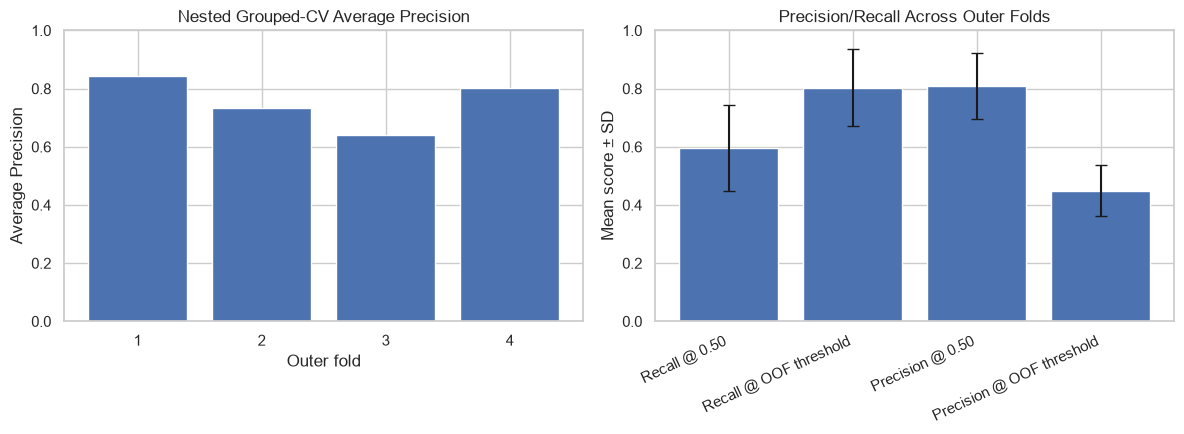

Saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_optimization_advanced\figures\05_nested_cv_performance.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

fold_x = np.arange(len(nested_folds_df))
axes[0].bar(fold_x, nested_folds_df["outer_validation_average_precision"].to_numpy())
axes[0].set_xticks(fold_x, nested_folds_df["outer_fold"].astype(str).tolist())
axes[0].set_title("Nested Grouped-CV Average Precision")
axes[0].set_xlabel("Outer fold")
axes[0].set_ylabel("Average Precision")
axes[0].set_ylim(0, 1)

metric_names = ["recall_at_050", "recall_at_oof_threshold", "precision_at_050", "precision_at_oof_threshold"]
metric_means = [float(nested_folds_df[name].mean()) for name in metric_names]
metric_stds = [float(nested_folds_df[name].std(ddof=1)) if len(nested_folds_df) > 1 else 0.0 for name in metric_names]
metric_labels = ["Recall @ 0.50", "Recall @ OOF threshold", "Precision @ 0.50", "Precision @ OOF threshold"]
pos = np.arange(len(metric_names))
axes[1].bar(pos, metric_means, yerr=metric_stds, capsize=4)
axes[1].set_xticks(pos, metric_labels, rotation=25, ha="right")
axes[1].set_title("Precision/Recall Across Outer Folds")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean score ± SD")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_nested_cv_performance.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", FIGURE_DIR / "05_nested_cv_performance.png")

## Cell 10 — Final TPE search using all eligible baseline records

In [10]:
# This search selects a deployable configuration after the nested-CV estimate has been saved.
# These full-data tuning scores are for model selection/deployment, not a final unbiased test score.
final_cv_splits = make_grouped_splits(X_morgan, y, groups, INNER_SPLITS, RANDOM_STATE + 5000)
final_searches = {}
final_search_rows = []

for family_index, family in enumerate(MODEL_NAMES):
    X_family_all = feature_matrix(family, X_desc, X_morgan)
    def objective_final(trial):
        params = suggest_params(trial, family)
        scores = []
        for fit_idx, val_idx in final_cv_splits:
            estimator = build_estimator(family, params)
            estimator.fit(X_family_all[fit_idx], y[fit_idx])
            val_prob = estimator.predict_proba(X_family_all[val_idx])[:, 1]
            scores.append(average_precision_score(y[val_idx], val_prob))
        return float(np.mean(scores))

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=RANDOM_STATE + 6000 + family_index),
        study_name=f"final_{family.replace(' ', '_')}",
    )
    print(f"\nFinal tuning: {family}")
    study.optimize(objective_final, n_trials=FINAL_TRIALS, show_progress_bar=False)
    final_searches[family] = study
    for trial in study.trials:
        final_search_rows.append({
            "family": family,
            "trial_number": trial.number,
            "trial_state": str(trial.state),
            "grouped_cv_average_precision": trial.value,
            "params_json": json.dumps(trial.params, sort_keys=True, default=str),
        })
    print(f"Best grouped-CV AP: {study.best_value:.4f}")

final_search_df = pd.DataFrame([
    {"family": family, "best_grouped_cv_ap": float(study.best_value),
     "best_params_json": json.dumps(study.best_params, sort_keys=True, default=str)}
    for family, study in final_searches.items()
]).sort_values("best_grouped_cv_ap", ascending=False).reset_index(drop=True)
final_trials_df = pd.DataFrame(final_search_rows)
display(final_search_df)
final_search_df.to_csv(REPORT_DIR / "05_final_model_family_comparison.csv", index=False, encoding="utf-8-sig")
final_trials_df.to_csv(REPORT_DIR / "05_final_tpe_trial_history.csv", index=False, encoding="utf-8-sig")


Final tuning: Random Forest — Morgan
Best grouped-CV AP: 0.7544

Final tuning: Extra Trees — Morgan
Best grouped-CV AP: 0.7550

Final tuning: Logistic Regression — Morgan
Best grouped-CV AP: 0.7322

Final tuning: Logistic Regression — descriptors
Best grouped-CV AP: 0.5257

Final tuning: Gradient Boosting — descriptors
Best grouped-CV AP: 0.6092


,family,best_grouped_cv_ap,best_params_json
0,Extra Trees — Morgan,0.754973,"{""class_weight"": ""balanced"", ""max_depth"": 25, ..."
1,Random Forest — Morgan,0.754417,"{""class_weight"": null, ""max_depth"": 32, ""max_f..."
2,Logistic Regression — Morgan,0.732150,"{""C"": 0.09536186820703219, ""class_weight"": ""ba..."
3,Gradient Boosting — descriptors,0.609204,"{""learning_rate"": 0.10305187273703541, ""max_de..."
4,Logistic Regression — descriptors,0.525701,"{""C"": 96.10300600202488, ""class_weight"": null}"


## Cell 11 — Select final configuration and develop a threshold from grouped OOF predictions

Selected deployable candidate: Extra Trees — Morgan
Best grouped-CV AP (for selection, not unbiased performance): 0.755
Best parameters:
{
  "class_weight": "balanced",
  "max_depth": 25,
  "max_features": 0.2,
  "min_samples_leaf": 2,
  "min_samples_split": 8,
  "n_estimators": 350
}
OOF-selected F2 threshold: 0.2556
OOF precision / recall / F2: 0.5011 0.7857 0.7056


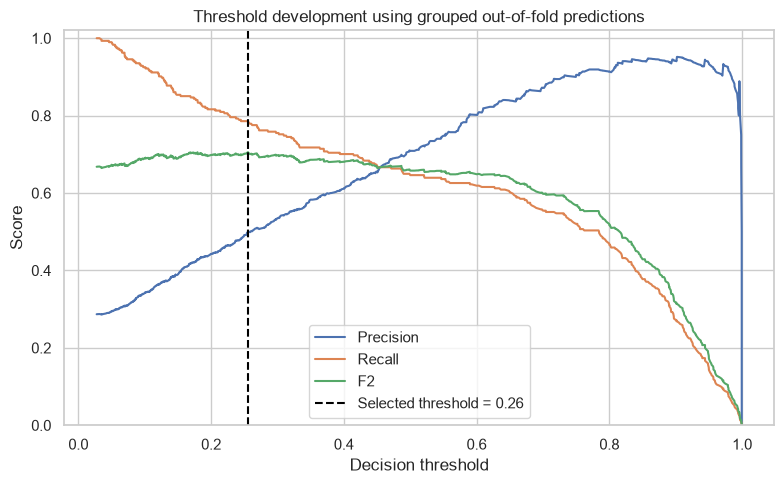

In [11]:
# Candidate is selected only from grouped-CV scores; no holdout metrics enter this decision.
best_family = str(final_search_df.iloc[0]["family"])
best_params = final_searches[best_family].best_params
final_estimator = build_estimator(best_family, best_params)
X_final = feature_matrix(best_family, X_desc, X_morgan)

# OOF scores from grouped folds are used to develop a threshold for later screening.
final_oof_prob = cross_val_predict(
    final_estimator, X_final, y, cv=final_cv_splits,
    method="predict_proba", n_jobs=1
)[:, 1]
threshold_info = threshold_for_fbeta(y, final_oof_prob, beta=2.0)

print("Selected deployable candidate:", best_family)
print("Best grouped-CV AP (for selection, not unbiased performance):", round(float(final_searches[best_family].best_value), 4))
print("Best parameters:")
print(json.dumps(best_params, indent=2, sort_keys=True, default=str))
print("OOF-selected F2 threshold:", round(threshold_info["threshold"], 4))
print("OOF precision / recall / F2:", round(threshold_info["precision"], 4), round(threshold_info["recall"], 4), round(threshold_info["f2"], 4))

threshold_curve_rows = []
for thr in np.unique(np.concatenate([np.linspace(0.05, 0.95, 91), final_oof_prob])):
    p = (final_oof_prob >= thr).astype(int)
    threshold_curve_rows.append({
        "threshold": float(thr),
        "precision": float(precision_score(y, p, zero_division=0)),
        "recall": float(recall_score(y, p, zero_division=0)),
        "f1": float(f1_score(y, p, zero_division=0)),
        "f2": float(fbeta_score(y, p, beta=2, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, p)),
        "mcc": float(matthews_corrcoef(y, p)),
    })
threshold_curve_df = pd.DataFrame(threshold_curve_rows)
threshold_curve_df.to_csv(REPORT_DIR / "05_final_oof_threshold_curve.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(8, 5))
plt.plot(threshold_curve_df["threshold"], threshold_curve_df["precision"], label="Precision")
plt.plot(threshold_curve_df["threshold"], threshold_curve_df["recall"], label="Recall")
plt.plot(threshold_curve_df["threshold"], threshold_curve_df["f2"], label="F2")
plt.axvline(threshold_info["threshold"], color="black", linestyle="--", label=f"Selected threshold = {threshold_info['threshold']:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.ylim(0, 1.02)
plt.title("Threshold development using grouped out-of-fold predictions")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_final_oof_threshold_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## Cell 12 — Fit final deployable model on all eligible baseline records

In [12]:
# After nested-CV evaluation is recorded, fit the selected configuration on all eligible rows.
# Do not interpret in-sample fitted predictions as validation performance.
final_estimator.fit(X_final, y)

final_bundle = {
    "model": final_estimator,
    "model_family": best_family,
    "feature_type": "morgan" if not best_family.endswith("descriptors") else "descriptors",
    "descriptor_names": descriptor_names,
    "threshold": float(threshold_info["threshold"]),
    "target_column": "label",
    "target_semantics": {0: "dataset-defined non-toxic label", 1: "dataset-defined toxic label"},
    "random_state": RANDOM_STATE,
    "training_rows": int(len(y)),
    "structure_grouped_nested_cv_outer_splits": OUTER_SPLITS,
    "inner_splits": INNER_SPLITS,
    "best_parameters": best_params,
    "warning": "Research screening model; not a regulatory or field-risk assessment.",
}
MODEL_PATH = MODEL_DIR / "05_advanced_tuned_candidate.joblib"
joblib.dump(final_bundle, MODEL_PATH)
print("Saved final deployable model bundle:", MODEL_PATH)

# Save the nested OOF records separately from the full-data fitted model.
nested_oof_df.to_csv(REPORT_DIR / "05_nested_cv_oof_predictions.csv", index=False, encoding="utf-8-sig")
print("Nested-CV predictions remain the primary performance evidence; full-data fitting is for deployment.")

Saved final deployable model bundle: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\models\05_advanced_tuned_candidate.joblib
Nested-CV predictions remain the primary performance evidence; full-data fitting is for deployment.


## Cell 13 — Save summary and reproducibility manifest

In [13]:
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

raw_hash = file_sha256(RAW_PATH) if RAW_PATH.is_file() else None
manifest_raw_hash = phase03_manifest.get("raw_data_sha256") or phase03_manifest.get("raw_sha256")

summary = {
    "project": "BeeSafe AI",
    "phase": "05 — Advanced Optimization and Nested Grouped CV",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "n_baseline_records": int(n),
    "n_structure_groups": int(metadata["structure_group"].nunique()),
    "class_counts": {str(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()},
    "primary_evaluation": "mean and standard deviation across nested outer structure-grouped CV folds",
    "outer_splits": OUTER_SPLITS,
    "inner_splits": INNER_SPLITS,
    "outer_tpe_trials_per_family": OUTER_TRIALS,
    "final_tpe_trials_per_family": FINAL_TRIALS,
    "optuna_sampler": "TPESampler",
    "selection_metric": "Average Precision",
    "nested_cv_mean_ap": float(nested_folds_df["outer_validation_average_precision"].mean()),
    "nested_cv_std_ap": float(nested_folds_df["outer_validation_average_precision"].std(ddof=1)),
    "nested_cv_mean_roc_auc": float(nested_folds_df["outer_validation_roc_auc"].mean()),
    "selected_deployable_model_family": best_family,
    "final_grouped_cv_ap_for_selection_only": float(final_searches[best_family].best_value),
    "selected_oof_f2_threshold_for_deployment": float(threshold_info["threshold"]),
    "selected_oof_precision": float(threshold_info["precision"]),
    "selected_oof_recall": float(threshold_info["recall"]),
    "selected_oof_f2": float(threshold_info["f2"]),
    "model_path": str(MODEL_PATH),
    "nested_cv_metrics_path": str(REPORT_DIR / "05_nested_cv_outer_fold_metrics.csv"),
    "final_search_results_path": str(REPORT_DIR / "05_final_model_family_comparison.csv"),
    "raw_dataset_sha256": raw_hash,
    "phase03_manifest_raw_hash": manifest_raw_hash,
    "raw_hash_matches_phase03_manifest": (raw_hash == manifest_raw_hash) if raw_hash and manifest_raw_hash else None,
    "phase04_holdout_note": "Earlier Phase 04 holdout results were inspected. This notebook does not reuse that holdout as a fresh final test; nested grouped CV is the primary estimate.",
    "limitations": [
        "Performance reflects curated ApisTox dataset labels, not direct field-level ecological impact.",
        "Nested grouped CV reduces model-selection optimism but does not replace external/prospective validation.",
        "The baseline excludes 10 Phase 02 identity-flagged records under the Phase 03 conservative policy.",
        "Decision threshold is an operational screening choice and does not establish probability calibration.",
    ],
}
SUMMARY_PATH = REPORT_DIR / "05_advanced_optimization_summary.json"
with SUMMARY_PATH.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("=" * 72)
print("BEESAFE AI — PHASE 05 COMPLETE")
print("=" * 72)
print("Nested grouped-CV mean AP:", round(summary["nested_cv_mean_ap"], 4))
print("Nested grouped-CV AP standard deviation:", round(summary["nested_cv_std_ap"], 4))
print("Nested grouped-CV mean ROC-AUC:", round(summary["nested_cv_mean_roc_auc"], 4))
print("Selected deployment model family:", best_family)
print("OOF threshold for screening:", round(threshold_info["threshold"], 4))
print("Final model:", MODEL_PATH)
print("Summary:", SUMMARY_PATH)
print("Raw dataset unchanged by this notebook: this notebook only reads the original CSV.")
print("Reminder: use nested grouped-CV results as the primary estimate; the final full-data tuning score is for selection only.")

BEESAFE AI — PHASE 05 COMPLETE
Nested grouped-CV mean AP: 0.7548
Nested grouped-CV AP standard deviation: 0.088
Nested grouped-CV mean ROC-AUC: 0.8176
Selected deployment model family: Extra Trees — Morgan
OOF threshold for screening: 0.2556
Final model: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\models\05_advanced_tuned_candidate.joblib
Summary: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_optimization_advanced\05_advanced_optimization_summary.json
Raw dataset unchanged by this notebook: this notebook only reads the original CSV.
Reminder: use nested grouped-CV results as the primary estimate; the final full-data tuning score is for selection only.


## Output checklist

The notebook saves its main outputs to `reports/model_optimization_advanced/` and the final model bundle to `models/05_advanced_tuned_candidate.joblib`.

Key outputs include:
- `05_nested_cv_outer_fold_metrics.csv` — outer-fold performance of the complete selection procedure.
- `05_nested_cv_summary.csv` — mean, standard deviation, minimum, and maximum across outer folds.
- `05_nested_cv_trial_history.csv` — hyperparameter trials run inside each outer fold.
- `05_nested_cv_oof_predictions.csv` — one outer-fold prediction per eligible record.
- `05_final_model_family_comparison.csv` and `05_final_tpe_trial_history.csv` — final tuning results used to choose the deployable model.
- `05_final_oof_threshold_curve.csv` and `figures/05_final_oof_threshold_curve.png` — threshold development from grouped out-of-fold predictions.
- `05_advanced_optimization_summary.json` — configuration, metrics, limitations, and provenance details.

**Interpretation:** nested-CV values are estimates from folds, with variability reported. The full-data CV score used to select the final deployment model is not the final generalization estimate. To make a strong external claim, evaluate once on a genuinely new external/prospective dataset.